# Team Zero — Scam Message Checker: the word-based model

**Problem:** scam SMS and chat messages trick people into paying fake fees or sharing bank details,
and most people cannot tell a scam from a genuine message until the money is gone.

**This notebook** trains the first layer of our checker: a word-based ML model (TF-IDF + logistic regression)
that scores how scam-like a message's wording is. The other layers (scam tactics, payment-details warning,
link checks, receiver check, Granite explanation) live in `checker/` and the API.

It runs on **IBM LinuxONE** (s390x) inside IBM's Jupyter container.

## 1. Where this runs

In [1]:
import platform
import sys

import pandas as pd
import sklearn

print("Machine:", platform.machine())  # s390x = IBM Z / LinuxONE
print("OS:", platform.system(), platform.release())
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

Machine: s390x
OS: Linux 6.8.0-147-generic
Python: 3.12.15
pandas: 3.0.6 | scikit-learn: 1.9.0


## 2. Load the data

UCI **SMS Spam Collection** (Almeida & Gómez Hidalgo, CC BY 4.0): 5,574 English SMS labelled `ham` or `spam`.
The file is tab-separated with no header row. `QUOTE_NONE` is needed because some messages contain `"`;
without it pandas merges lines and reads 5,572 rows.

In [2]:
import csv

pd.set_option("display.max_colwidth", None)

df = pd.read_csv(
    "data/sms_spam_collection/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    quoting=csv.QUOTE_NONE,
)
print(df.shape)
df.head()

(5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 3. Explore

In [3]:
print("Empty values per column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Empty values per column:
label      0
message    0
dtype: int64
Duplicate rows: 403


In [4]:
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

label
ham     4827
spam     747
Name: count, dtype: int64
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


In [5]:
df["length"] = df["message"].str.len()
df.groupby("label")["length"].mean().round(1)

label
ham      71.5
spam    138.7
Name: length, dtype: float64

In [6]:
import re
from collections import Counter

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS


def top_words(label, n=15):
    words = Counter()
    for m in df[df["label"] == label]["message"]:
        for w in re.findall(r"[a-z]+", m.lower()):
            if w not in ENGLISH_STOP_WORDS and len(w) > 1:
                words[w] += 1
    return words.most_common(n)


print("SPAM:", top_words("spam"))
print("HAM: ", top_words("ham"))

SPAM: [('free', 228), ('txt', 170), ('ur', 144), ('mobile', 129), ('stop', 128), ('text', 126), ('claim', 113), ('reply', 104), ('www', 98), ('prize', 93), ('just', 79), ('cash', 76), ('won', 76), ('uk', 74), ('win', 72)]
HAM:  [('gt', 318), ('lt', 316), ('just', 297), ('ok', 288), ('ll', 266), ('ur', 247), ('know', 237), ('good', 235), ('got', 234), ('like', 234), ('come', 231), ('day', 218), ('love', 205), ('time', 202), ('going', 169)]


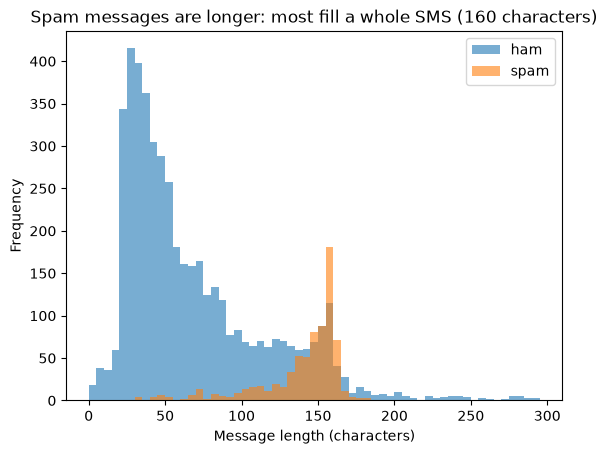

In [7]:
import matplotlib.pyplot as plt

df[df["label"] == "ham"]["length"].plot.hist(bins=range(0, 300, 5), alpha=0.6, label="ham")
df[df["label"] == "spam"]["length"].plot.hist(bins=range(0, 300, 5), alpha=0.6, label="spam")
plt.xlabel("Message length (characters)")
plt.title("Spam messages are longer: most fill a whole SMS (160 characters)")
plt.legend()
plt.show()

## 4. Prepare

Drop duplicates (so the same message cannot end up in both training and test data), separate the input
(`X`, the message) from the answer (`y`: 1 = spam, 0 = ham), and keep 20% of the messages aside for testing.
`stratify=y` keeps the same ham/spam mix in both parts.

In [8]:
from sklearn.model_selection import train_test_split

df = df.drop_duplicates()
X = df["message"]
y = (df["label"] == "spam").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Unique messages:", len(df))
print("Train:", len(X_train), "| Test:", len(X_test))
print("Spam share - train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Unique messages: 5171
Train: 4136 | Test: 1035
Spam share - train: 0.126 | test: 0.127


## 5. Model 1: TF-IDF + logistic regression

TF-IDF turns each message into one score per word (high for words that are frequent in the message and rare
overall). Logistic regression learns one weight per word and turns the sum into a probability.
`class_weight="balanced"`: spam is only 13% of the data, so mistakes on spam count more during training.
Both steps are kept together in one **pipeline**, so the saved model takes plain text.

              precision    recall  f1-score   support

         ham      0.988     0.985     0.986       904
        spam      0.896     0.916     0.906       131

    accuracy                          0.976      1035
   macro avg      0.942     0.950     0.946      1035
weighted avg      0.976     0.976     0.976      1035



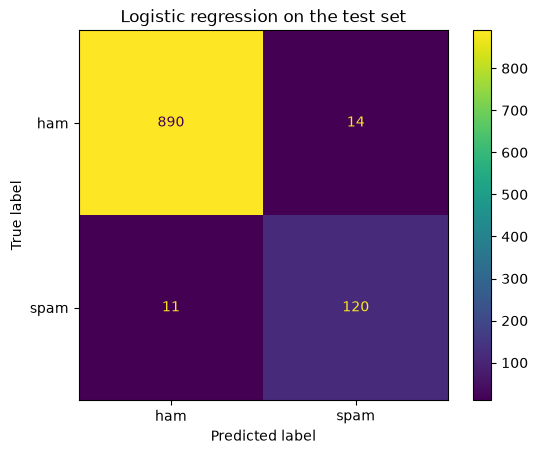

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.pipeline import Pipeline

logreg = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)
logreg_pred = logreg.predict(X_test)

print(classification_report(y_test, logreg_pred, target_names=["ham", "spam"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, logreg_pred, display_labels=["ham", "spam"])
plt.title("Logistic regression on the test set")
plt.show()

## 6. Model 2: Naive Bayes (for comparison)

A classic text model that counts how often each word appears in spam versus ham.

              precision    recall  f1-score   support

         ham      0.949     1.000     0.974       904
        spam      1.000     0.626     0.770       131

    accuracy                          0.953      1035
   macro avg      0.974     0.813     0.872      1035
weighted avg      0.955     0.953     0.948      1035



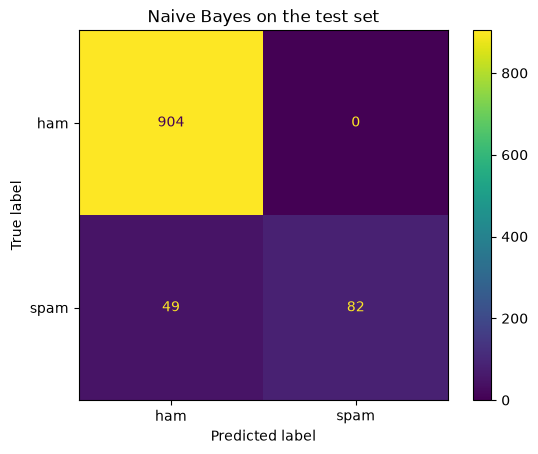

In [10]:
from sklearn.naive_bayes import MultinomialNB

nbayes = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("model", MultinomialNB()),
])
nbayes.fit(X_train, y_train)
nbayes_pred = nbayes.predict(X_test)

print(classification_report(y_test, nbayes_pred, target_names=["ham", "spam"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, nbayes_pred, display_labels=["ham", "spam"])
plt.title("Naive Bayes on the test set")
plt.show()

## 7. Compare and choose

**Precision** (spam): when the model says spam, how often is it right?
**Recall** (spam): of all real spam, how much did it catch? For a scam checker, missing a scam is the worse mistake,
so we pick the model with the better **F1** (the balance of both) and look closely at recall.

In [11]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

results = pd.DataFrame(
    {
        name: {
            "accuracy": accuracy_score(y_test, pred),
            "precision (spam)": precision_score(y_test, pred),
            "recall (spam)": recall_score(y_test, pred),
            "F1 (spam)": f1_score(y_test, pred),
        }
        for name, pred in [("logistic regression", logreg_pred), ("naive bayes", nbayes_pred)]
    }
).round(3)
print(results)

best_name = results.loc["F1 (spam)"].idxmax()
best = logreg if best_name == "logistic regression" else nbayes
print("\nChosen model:", best_name)

                  logistic regression  naive bayes
accuracy                        0.976        0.953
precision (spam)                0.896        1.000
recall (spam)                   0.916        0.626
F1 (spam)                       0.906        0.770

Chosen model: logistic regression


## 8. Risk bands

The model gives a spam probability from 0 to 1. The checker shows it as a band:
**Safe** below 0.30, **Suspicious** from 0.30 to below 0.70, **Scam** from 0.70.
The same thresholds are used by the API (`checker/model.py`), so the notebook and the app always agree.

In [12]:
from checker.model import SAFE_BELOW, SCAM_FROM, band

test_prob = best.predict_proba(X_test)[:, 1]
bands = pd.Series([band(p) for p in test_prob], index=X_test.index, name="band")
truth = y_test.map({0: "ham", 1: "spam"}).rename("truth")

print(f"Safe < {SAFE_BELOW} <= Suspicious < {SCAM_FROM} <= Scam")
pd.crosstab(truth, bands)[["safe", "suspicious", "scam"]]

Safe < 0.3 <= Suspicious < 0.7 <= Scam


band,safe,suspicious,scam
truth,,,
ham,846,54,4
spam,7,16,108


## 9. Our own test messages (modern scams, Malay)

These 20 messages are made up (created by the team with AI assistance) to cover cases the 2011 dataset lacks:
modern scams, Malay messages, and a normal-looking bill with a swapped bank account.
The word model alone misses several of them, which is why the checker adds rule-based layers on top.

In [13]:
tests = pd.read_csv("data/test_messages/test_messages.csv")
tests["model_probability"] = best.predict_proba(tests["message"])[:, 1].round(3)
tests["model_band"] = [band(p) for p in tests["model_probability"]]
tests["match"] = tests["model_band"] == tests["expected_verdict"]

print("Word model matches the expected verdict for", tests["match"].sum(), "of", len(tests), "messages")
tests[["id", "language", "expected_verdict", "model_probability", "model_band", "match", "message"]]

Word model matches the expected verdict for 12 of 22 messages


,id,language,expected_verdict,model_probability,model_band,match,message
0,1,en,safe,0.055,safe,True,"Hi mum, I'll be home by 7. Can you keep some rice for me?"
1,2,ms,safe,0.179,safe,True,Jom makan tengah hari esok? Aku belanja.
2,3,en,safe,0.091,safe,True,Meeting moved to 3pm in room B. See you there.
3,4,en,safe,0.054,safe,True,"Bro, later we go mamak lah, 8pm ok?"
4,5,ms,safe,0.180,safe,True,"Assalamualaikum, kelas esok dibatalkan. Jumpa minggu depan."
5,6,en,safe,0.604,suspicious,False,Your TAC for login is 482913. Do not share this code with anyone.
6,7,en,safe,0.570,suspicious,False,Your parcel has been delivered. Track it at https://www.pos.com.my
7,8,en,scam,0.997,scam,True,Congratulations! You have won a FREE holiday. Text WIN to 81234 to claim your prize now!
8,9,ms,scam,0.634,suspicious,False,"Tahniah! Anda pemenang cabutan bertuah RM5,000. Tuntut hadiah anda di http://203.0.113.45/claim"
9,10,en,scam,0.536,suspicious,False,Your bank account has been suspended due to unusual activity. Verify within 24 hours at http://rnaybank2u-secure.xyz/login or it will be closed.


## 10. Save the model

The whole pipeline (TF-IDF + model) is saved as one file in `models/`, then loaded back to check it gives
the same answers. The API loads this file. Model files are not committed to git: the model is trained here,
on LinuxONE.

In [14]:
import os

import joblib

os.makedirs("models", exist_ok=True)
model_path = "models/scam_model.joblib"
joblib.dump(best, model_path)

reloaded = joblib.load(model_path)
same = (reloaded.predict_proba(X_test)[:, 1] == best.predict_proba(X_test)[:, 1]).all()
print("Saved:", model_path, "| size:", os.path.getsize(model_path), "bytes | reload gives same answers:", same)

Saved: models/scam_model.joblib | size: 216772 bytes | reload gives same answers: True
